# 环境导入

In [19]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display, HTML


# 关闭坐标轴负号的特殊显示（否则负号会渲染成方块）
plt.rcParams['axes.unicode_minus'] = False

# 按优先级排列的候选常用中文字体名
_cjk_candidates = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Noto Sans CJK SC',
                  'Arial Unicode MS', 'WenQuanYi Micro Hei', 'Source Han Sans SC']

# 最终选中的字体名；初始为 None 表示还没找到
_chosen = None

# 第一轮：按优先级逐个检查候选字体是否存在
for _name in _cjk_candidates:
    try:
        # findfont 能成功返回，说明系统安装了该字体
        fm.findfont(_name, fallback_to_default=False)
        # 记录第一个可用字体并结束查找
        _chosen = _name
        break
    except Exception:
        # 该字体未安装，跳过并尝试下一个候选
        continue

# 兜底：候选全都没命中时，扫描系统已安装的全部字体
if _chosen is None:
    # 判断一个字体"像中文字体"的关键词列表
    _font_keywords = ('YaHei', 'SimHei', 'Hei', 'CJK', 'PingFang',
                      'WenQuanYi', 'Noto Sans CJK', 'Song', 'Kai', 'Ming')
    # 逐个检查系统字体列表
    for _f in fm.fontManager.ttflist:
        # 当前字体名是否包含任一中文关键词（初始认为不是）
        _is_cjk_like = False
        for _k in _font_keywords:
            if _k in _f.name:
                # 命中关键词，判定该字体可显示中文
                _is_cjk_like = True
                break
        if _is_cjk_like:
            # 取第一个命中的字体作为中文字体并结束扫描
            _chosen = _f.name
            break

# 应用最终选定的字体，并把结果告诉用户
if _chosen:
    plt.rcParams['font.sans-serif'] = [_chosen]
    print(f'中文字体: {_chosen}')
else:
    print('警告: 未找到中文字体，图表中文可能显示为方块')
%matplotlib inline


# ═══════════════════════════════════════════════════
# 路径引导：让 Notebook 能导入 src 包，并正确定位项目根目录
# ═══════════════════════════════════════════════════
import sys
from pathlib import Path

# Notebook 就在项目根目录下运行 → 当前工作目录即项目根目录；
# 若日后再放进 notebooks/ 子目录，则取上一层（保留这层兼容判断）
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 后续所有 cell 统一用 `from src.xxx import ...` 导入；
# 数据 / 结果路径由 src/config.py 集中管理（与命令行入口共用同一套路径）
from src.config import DATA_DIR, RESULTS_DIR

print(f'项目根目录: {PROJECT_ROOT}')
print(f'数据目录  : {DATA_DIR}')
print(f'结果目录  : {RESULTS_DIR}')


中文字体: Microsoft YaHei
项目根目录: D:\Code\ecommerce-user-behavior-segmentation
数据目录  : D:\Code\ecommerce-user-behavior-segmentation\data
结果目录  : D:\Code\ecommerce-user-behavior-segmentation\results


In [ ]:
%%sql


# EDA探索性数据分析

## 数据加载与预处理

数据源为 7 个月用户面板（`data/panel_7months.parquet`，user_id 哈希抽样 5%，约 78 万用户）。取 **10 月事件**用于建模/EDA，**11 月事件**用于验证。


In [20]:
# ============================================================
# 数据加载：只读 7 个月面板中的 10 / 11 两个月
# （面板是全量 7 个月，这里按月份行过滤，避免读入全量数据）
# → 10 月事件用于建模 / EDA，11 月事件用于时间外验证
# ============================================================

# 从配置读取面板文件路径
from src.config import PANEL_FILE
# 从 analysis 导入：面板读取函数 + 用户级特征构建函数
from src.analysis import load_panel, build_features

# 加载 10 月与 11 月的事件数据（只读建模/验证月，避免读全量）
panel = load_panel(PANEL_FILE, months=['2019-10', '2019-11'])

# 按月份拆出两个子集：
# 10 月事件用于建模
oct_events = panel[panel['month']=='2019-10']
# 11 月事件用于时间外验证
nov_events = panel[panel['month'] == '2019-11']

# 输出两个月各自的事件条数
print(f"10月事件数: {len(oct_events)} 条")
print(f"11月事件数: {len(nov_events)} 条")

# 与 analysis.py 共用同一套特征构建逻辑（单一事实来源）
# 截止时刻取该月最后一条事件的时间，保证特征口径与线上一致
oct_cutoff = oct_events['event_time'].max()
df = build_features(oct_events, oct_cutoff)

# 输出用户级特征表的规模：多少用户 × 多少特征
print(f"\n用户级特征表: {df.shape[0]} 用户 × {df.shape[1]} 特征")
df.head()


10月事件数: 2117423 条
11月事件数: 3391302 条

用户级特征表: 151447 用户 × 12 特征


,user_id,Purchase_Frequency,Total_Spending,Pages_Viewed,Session_Count,Estimated_Time,Cart_Products,Purchased_Products,Recency_Days,Exploration,Friction,Log_Friction
0,231943435,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0
1,240236728,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0
2,241587569,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0
3,278266184,0,0.0,28,14,1129.0,0,0,31,1.630707,0,0.0
4,290749523,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0


## 10月份数据总览

In [39]:
# ============================================================
# 数值特征概览：描述性统计 + 缺失值检查 + 偏度
# （判断各特征是否存在长尾 / 缺失，为后续变换做准备）
# ============================================================

# 参与数值统计的目标特征列（与后续建模口径保持一致）
target_numeric = ['Recency_Days', 'Purchase_Frequency', 'Total_Spending',
                  'Pages_Viewed', 'Estimated_Time', 'Cart_Products']



# 统计整张特征表的缺失值总数
miss = df.isnull().sum().sum()

# 根据缺失情况拼提示文案：无缺失显示 ✅，有缺失则显示具体个数
if miss == 0:
    miss_msg = '✅ 无缺失'
else:
    miss_msg = f'⚠️ {miss} 个'
print(f"缺失值: {miss_msg}\n")

# 对数值特征做描述性统计
summary = df[target_numeric].describe().T.round(2)
# 追加一列：各特征的偏度（|偏度| 越大说明分布越右偏/长尾）
summary['skew'] = df[target_numeric].skew().round(2)

display(summary)


缺失值: ✅ 无缺失



,count,mean,std,min,25%,50%,75%,max,skew
Recency_Days,151447.0,28.98,6.33,0.0,31.0,31.0,31.0,31.00,-3.21
Purchase_Frequency,151447.0,0.25,1.54,0.0,0.0,0.0,0.0,291.00,60.16
Total_Spending,151447.0,76.71,700.57,0.0,0.0,0.0,0.0,84781.78,50.47
Pages_Viewed,151447.0,13.42,30.75,0.0,2.0,4.0,13.0,2312.00,12.81
Estimated_Time,151447.0,714.79,1798.03,0.0,0.0,149.0,685.0,141713.00,12.71
Cart_Products,151447.0,0.17,0.61,0.0,0.0,0.0,0.0,21.00,7.73


                       count    mean      std  min   25%    50%    75%  \
Recency_Days        151447.0   28.98     6.33  0.0  31.0   31.0   31.0   
Purchase_Frequency  151447.0    0.25     1.54  0.0   0.0    0.0    0.0   
Total_Spending      151447.0   76.71   700.57  0.0   0.0    0.0    0.0   
Pages_Viewed        151447.0   13.42    30.75  0.0   2.0    4.0   13.0   
Estimated_Time      151447.0  714.79  1798.03  0.0   0.0  149.0  685.0   
Cart_Products       151447.0    0.17     0.61  0.0   0.0    0.0    0.0   

                          max   skew  
Recency_Days            31.00  -3.21  
Purchase_Frequency     291.00  60.16  
Total_Spending       84781.78  50.47  
Pages_Viewed          2312.00  12.81  
Estimated_Time      141713.00  12.71  
Cart_Products           21.00   7.73  


### 10月份数据总览解读：

1. **未购用户占比很高，需要先区分已购和未购用户**

    - 在 151,447 名用户中，有 133,927 人从未购买过，占比 88.4%；
    - 有过购买行为的用户仅占 11.6%。

    如果直接对所有用户，根据最近购买时间、购买频次和消费金额进行 RFM 聚类划分，由于大部分用户的购买频次和消费金额都是 0，聚类结果很容易集中在“从未购买”的一类，难以进一步区分不同用户的价值。因此，项目决定先将用户分为已购和未购两组，再分别进行细分。
2. **某些特征差异巨大，要先处理极端值**

    用户的消费金额和购买频次都呈现明显的长尾分布：大部分用户的数值很低，少数用户却非常高。例如，Total_Spending（总消费金额）的偏度约为 50，Purchase_Frequency（购买频次）的偏度约为 60。这意味着，少数高消费、高频次用户可能会影响用户分层的效果，固定数值区间或简单按分位数划分也不一定合适。因此，后续先对相关指标使用 log1p 变换（ln(1+x)），缩小极端值与普通用户之间的差距，再通过 GMM高斯混合模型动态识别用户群体的分界点，让分层更贴合实际数据分布。


### 10月份单变量分布可视化

Cell 07 的描述统计已给出偏度（skew≈50~60），这里用直方图直接看分布形状：

- **原始值**：几乎所有变量都**堆积在 0 附近**（消费 / 频次 / 加购的 0 值占比 88%~96%），右侧是极长的尾巴——绝大多数细节被挤压成一根竖线；
- **log1p 变换后**：长尾被压缩，才能看清真实形态——消费/频次是"大量 0 + 平滑正尾"，页数/时长近似单峰，加购是极端零膨胀；
- **Recency_Days**：未购用户全部落在兜底值（观察期长度），已购用户散布在左侧 → 印证"近度主要区分买没买"。

> 结论：这就是为什么后面所有指标用 **log1p 压缩**、阈值用 **GMM 动态拟合**（而不是固定分箱）——固定分箱会被长尾和零膨胀带偏。

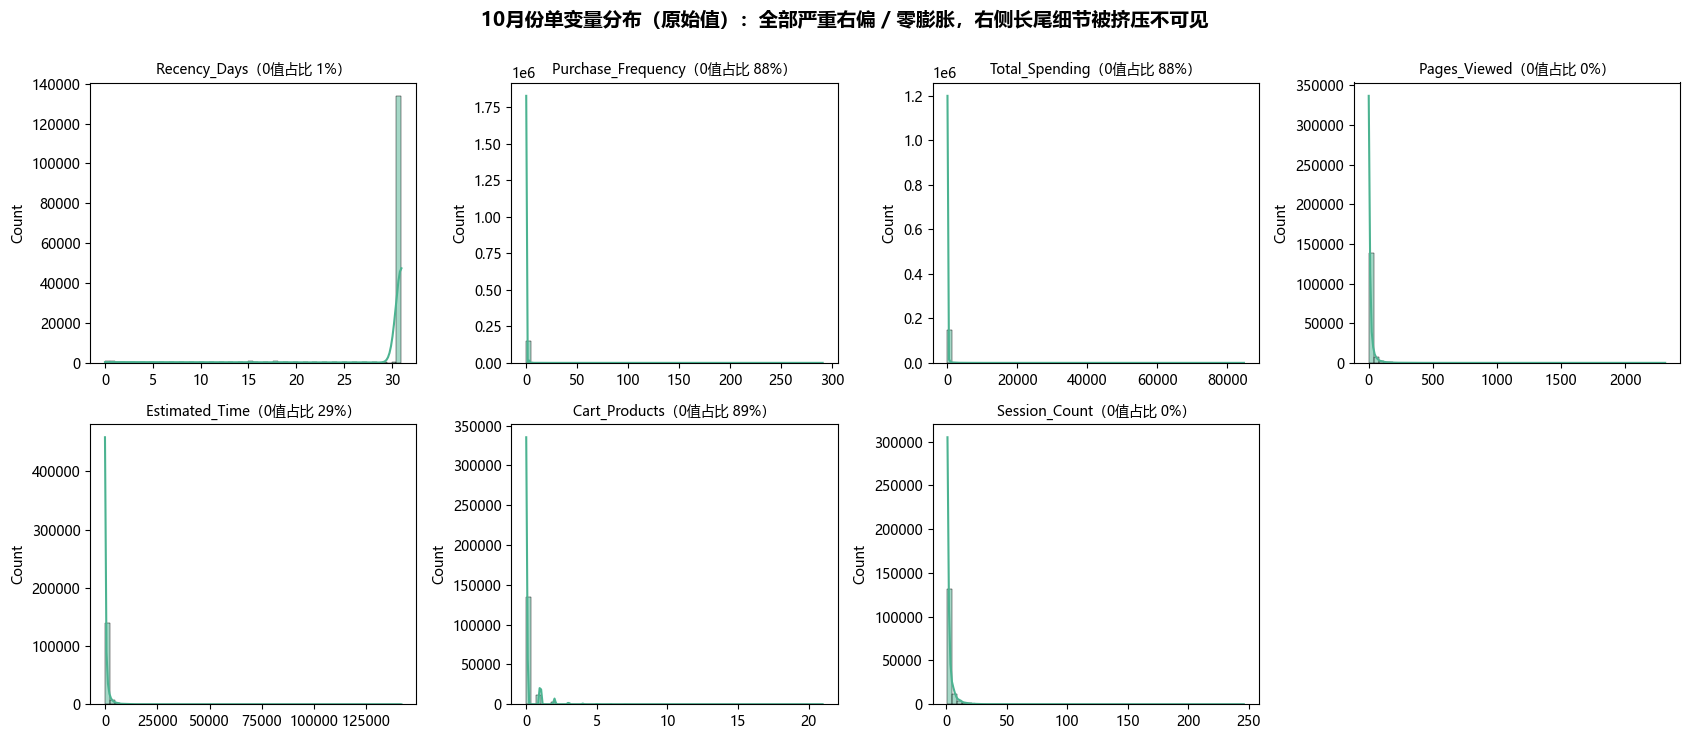

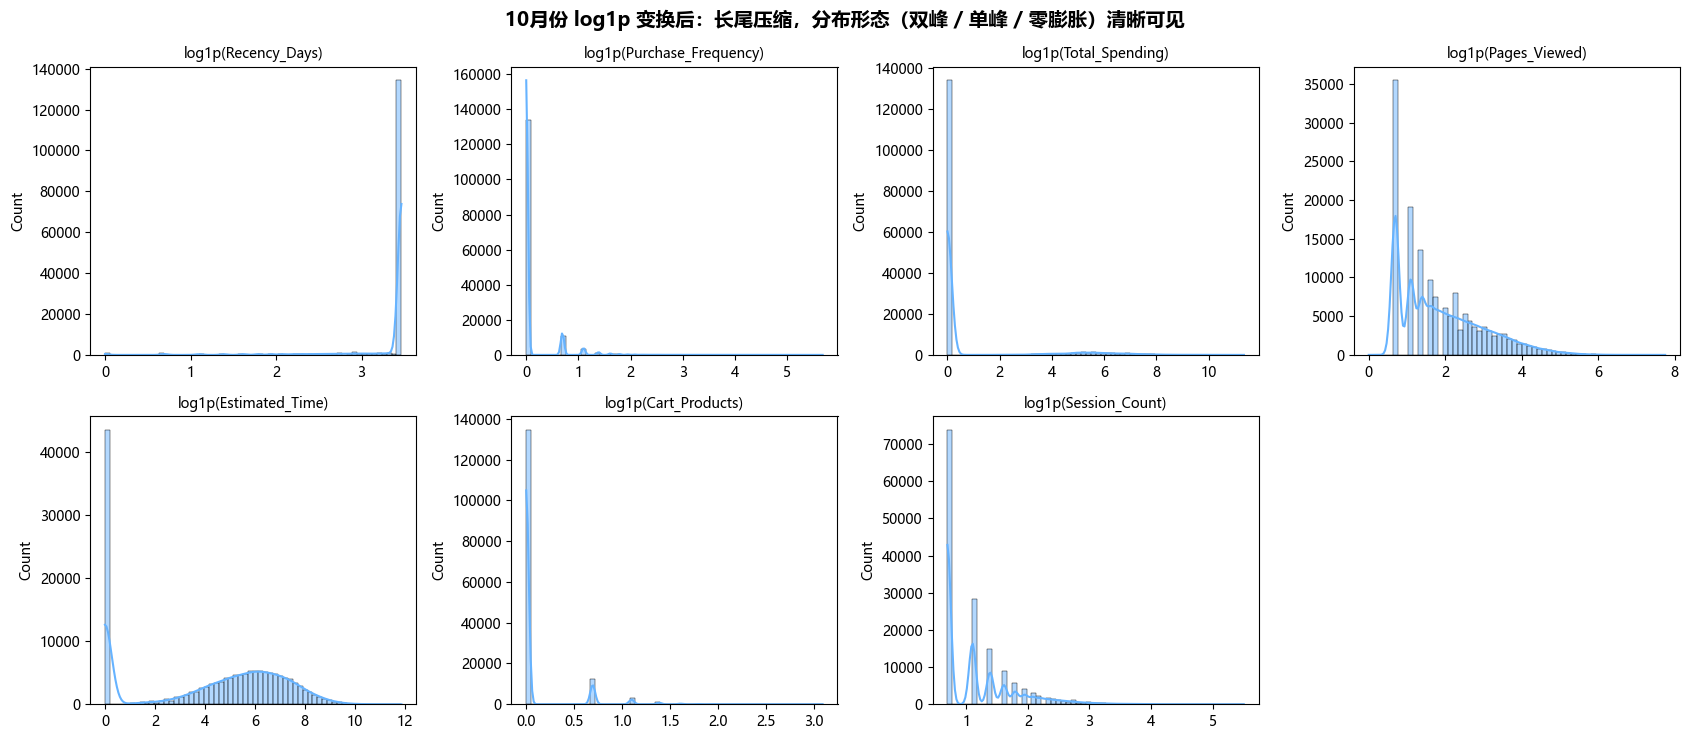

In [22]:
# ═══════════════════════════════════════════════════
# 单变量分布：原始值 vs log1p 变换（印证长尾 / 零膨胀）
# ═══════════════════════════════════════════════════
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 要画分布图的列：与数值特征一致的 7 个变量
# （target_numeric 6 个 + Session_Count 会话数，相关分析里也用这一组）
plot_cols = target_numeric + ['Session_Count']
# 变量个数（画 2x4 子图网格，实际只用到前 7 格）
n = len(plot_cols)

# ── 图 1：原始值分布（全范围）──
# 画图意图：展示"未做任何变换"时各变量的分布形态，
# 预期看到严重右偏 / 大量 0 堆积，右侧长尾细节被挤压不可见
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.ravel()
for ax, col in zip(axes, plot_cols):
    # 数值先截断到非负，避免负数干扰分布形态
    v = df[col].clip(lower=0)
    # 统计该变量中等于 0 的占比，用于标注"零膨胀"程度
    zero_pct = (v == 0).mean()
    # 画直方图 + 核密度曲线
    sns.histplot(v, bins=60, ax=ax, color='#4CB391', kde=True)
    # 标题标注变量名与 0 值占比
    ax.set_title(f'{col}（0值占比 {zero_pct:.0%}）', fontsize=10)
    ax.set_xlabel('')
# 关掉多余的空白子图（第 8 格没有数据）
for ax in axes[n:]:
    ax.axis('off')
# 整图大标题，说明图 1 要表达的核心信息
plt.suptitle('10月份单变量分布（原始值）：全部严重右偏 / 零膨胀，右侧长尾细节被挤压不可见',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ── 图 2：log1p 变换后的分布（长尾压缩后形态可见）──
# 画图意图：对数值取 log1p（log(1+x)）压缩长尾，
# 让原本被挤压不可见的分布形态（双峰 / 单峰 / 零膨胀）显形
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.ravel()
for ax, col in zip(axes, plot_cols):
    # 先 clip 到非负再 log1p 变换（避免对负值取对数）
    log1p_vals = np.log1p(df[col].clip(lower=0))
    # 画变换后值的直方图 + 核密度曲线
    sns.histplot(log1p_vals, bins=60, ax=ax, color='#66b3ff', kde=True)
    ax.set_title(f'log1p({col})', fontsize=10)
    ax.set_xlabel('')
# 关掉多余的空子图
for ax in axes[n:]:
    ax.axis('off')
# 整图大标题，说明图 2 要表达的核心信息
plt.suptitle('10月份 log1p 变换后：长尾压缩，分布形态（双峰 / 单峰 / 零膨胀）清晰可见',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [23]:
# ═══════════════════════════════════════════════════
# 偏度量化对比：原始值 vs log1p 变换后（判断长尾是否还需进一步处理）
# ═══════════════════════════════════════════════════


# 准备 log1p 变换后的数据：clip 下限 0 避免对 0/负数取对数
log1p_vals = np.log1p(df[plot_cols].clip(lower=0))
# 原始数据同样截断到非负，仅用于统计 0 值占比
clipped_vals = df[plot_cols].clip(lower=0)

# 构建对比表：每行一个特征，三列分别对比"原始偏度 / log1p 后偏度 / 0 值占比"
skew_table = pd.DataFrame({
    '原始偏度': df[plot_cols].skew().round(2),
    'log1p后偏度': log1p_vals.skew().round(2),
    '0值占比': (clipped_vals == 0).mean().round(3),
})


def grade_skew(absolute_skew):
    # 按 |偏度| 大小划分三个等级
    if absolute_skew < 1:
        return '近似对称(<1)'
    elif absolute_skew <= 2:
        return '中等偏(1~2)'
    else:
        return '严重偏(>2)'


# 新增一列：按 log1p 后偏度的绝对值标注偏度等级
skew_table['偏度等级(log1p后)'] = skew_table['log1p后偏度'].abs().map(grade_skew)
# 以 HTML 表格形式展示对比表
display(HTML(skew_table.to_html()))



,原始偏度,log1p后偏度,0值占比,偏度等级(log1p后)
Recency_Days,-3.21,-4.66,0.005,严重偏(>2)
Purchase_Frequency,60.16,3.87,0.884,严重偏(>2)
Total_Spending,50.47,2.69,0.884,严重偏(>2)
Pages_Viewed,12.81,0.83,0.000,近似对称(<1)
Estimated_Time,12.71,-0.35,0.287,近似对称(<1)
Cart_Products,7.73,3.32,0.889,严重偏(>2)
Session_Count,6.84,1.47,0.000,中等偏(1~2)



log1p 对页数/时长/会话非常有效（偏度 12.8/12.7/6.8 → 0.8/-0.4/1.5，接近对称）；

仍严重偏(>2)的是零膨胀类（频次/消费/加购，0 值占 88%+）：偏度来自 0 堆积，任何单调变换都无法消除——这是"大多数人不买"这一信息本身，不是尺度问题；

Recency_Days 负偏反而加大（-3.2 → -4.7）：log1p 把近度小值压缩得更密、未购兜底值在右端孤立，属 log1p 对窄值域变量的副作用；但不影响下游——价值指数只用分位数切分，对偏度稳健。

结论：本项目下游（GMM 找切分点 / LR 排序 / 分位数）均不假设正态性，log1p 已足够，无需再做进一步变换。若未来用对分布敏感的模型（KNN/朴素贝叶斯/直接回归），再进一步处理。

## 10月份多变量相关分析

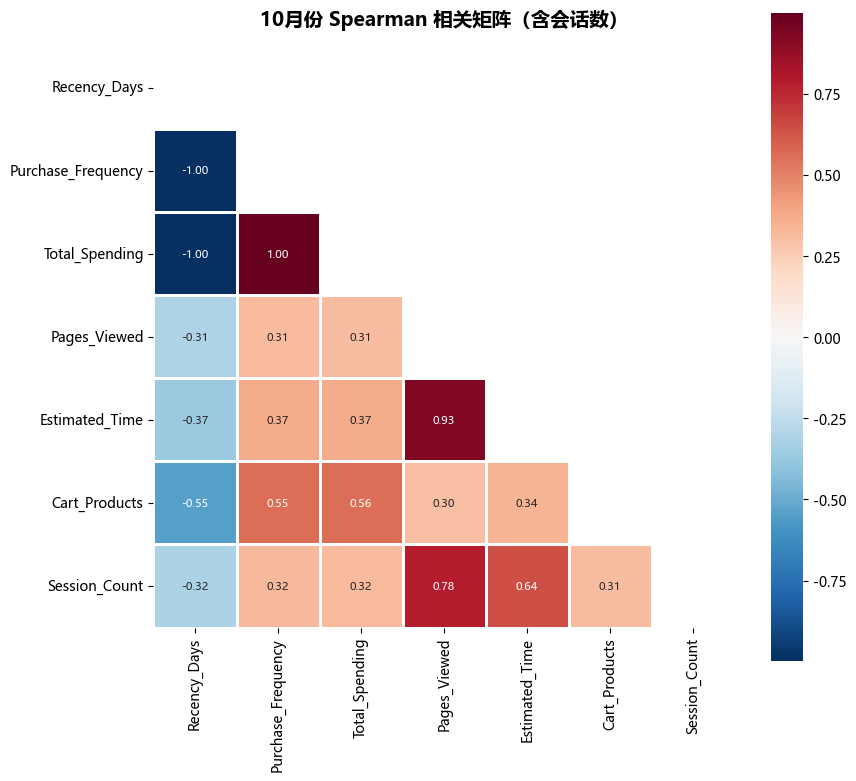

浏览三指标相关（Spearman）: 页数↔时长 r=0.925 | 页数↔会话 r=0.782 | 时长↔会话 r=0.643
加购 vs 浏览（Spearman）: r=0.303 → Friction 是与浏览独立的意图维度
未购用户占比: 88.4% | 消费偏度 50.5 | 频次偏度 60.2


In [24]:
# ============================================================
# 3a. 相关性分析：Spearman 相关热力图 + 关键相关系数
# 相关矩阵要包含会话数，是因为会话数与页数/时长同属"探索深度"指标
# ============================================================

# 参与相关分析的列：target_numeric 6 个数值特征 + 会话数
corr_cols = target_numeric + ['Session_Count']

# 准备画布（热力图用 9x8 的方形画布）
plt.figure(figsize=(9, 8))
# 计算这些特征的 Spearman 秩相关系数矩阵（对非线性单调关系更稳健）
corr = df[corr_cols].corr(method='spearman')
# 生成上三角掩码：只显示矩阵的下三角，避免重复展示对称的上半部分
mask = np.triu(np.ones_like(corr, dtype=bool))
# 画热力图：掩掉上三角、格子内标注相关系数、红蓝配色（RdBu_r）、中心色 0
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.8, annot_kws={'fontsize': 8})
# 图标题：说明该矩阵包含会话数
plt.title('10月份 Spearman 相关矩阵（含会话数）', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ── 关键相关系数（均为 Spearman，与热力图格子数值一致）──
import numpy as np

# 预先把要用到的浏览三指标两两相关系数算出来（与热力图同一口径）
r_pages_time = df["Pages_Viewed"].corr(df["Estimated_Time"], method="spearman")
r_pages_sess = df["Pages_Viewed"].corr(df["Session_Count"], method="spearman")
r_time_sess = df["Estimated_Time"].corr(df["Session_Count"], method="spearman")
# 打印浏览三指标的两两相关（页数↔时长 / 页数↔会话 / 时长↔会话）
print(f'浏览三指标相关（Spearman）: 页数↔时长 r={r_pages_time:.3f} | '
      f'页数↔会话 r={r_pages_sess:.3f} | '
      f'时长↔会话 r={r_time_sess:.3f}')

# 加购与浏览的相关性（验证 Friction 是否是独立于浏览的意图维度）
r_cart_pages = df["Cart_Products"].corr(df["Pages_Viewed"], method="spearman")
print(f'加购 vs 浏览（Spearman）: r={r_cart_pages:.3f} → Friction 是与浏览独立的意图维度')

# 汇总行级指标：未购用户占比 + 消费/频次的偏度
no_purchase_share = (df["Purchase_Frequency"] == 0).mean()
spend_skew = df["Total_Spending"].skew()
freq_skew = df["Purchase_Frequency"].skew()
print(f'未购用户占比: {no_purchase_share:.1%} | 消费偏度 {spend_skew:.1f} | '
      f'频次偏度 {freq_skew:.1f}')


### 相关分析解读：指标构建的依据

> **Spearman 秩相关**：把每个变量的数值换成**排名**再算相关——只比较"谁大谁小"的相对顺序，不看数值本身。两个优点：
> - 对极端值免疫（本项目消费/频次偏度 50~60，少数大额用户不会带偏结果）；
> - 对单调变换不变（如 log1p：排名不变，变换前后结果一样）。本项目相关分析统一用它，下方数字均与热力图格子一致。

- **浏览三指标高度相关**（页数、时长、会话〔一次连续访问〕）：页数↔时长 r≈0.93、页数↔会话 r≈0.78、时长↔会话 r≈0.64——三者衡量同一件事"探索深度"，等权平均合成单一 **Exploration**（避免三个冗余变量分别入模）；
- **加购与浏览弱相关**（r≈0.30）：加购未买（Friction）是与浏览**独立**的"购买意图受阻"维度——这正是未购人群首购潜力识别不依赖浏览量的依据；
- **近度（距最近一次购买的天数，RFM 的 R）与购买完全负相关**（r≈−1.00）：未购用户近度恒为回填值、已购用户近度小——近度主要区分"买没买"，所以价值指数只在已购用户内部计算；
- **已购内部**：消费↔频次 r≈0.53、频次↔近度 r≈−0.22——维度间部分相关但不完全冗余，等权相加的价值指数合理。

 EDA → 后续分析的因果逻辑

| EDA 发现 | 决定的处理 | 对应章节 |
|---|---|---|
| 未购占 88.4%，RFM 对零购买用户失效 | 先分流（已购 / 未购）再分层 | 分层 |
| 消费 / 频次长尾（skew≈50~60） | log1p 变换 + GMM 动态阈值（不用固定分箱） | 分层 |
| 浏览三指标高相关（0.59~0.86） | 合成单一探索度 Exploration | 分层 |
| 加购与浏览弱相关（r≈0.35） | Friction 作独立维度，未购人群专用 | 分层 |
| 未购 92% 无加购（零膨胀） | log(Friction) 阈值退化为"有加购即高摩擦" | 分层 |
| 近度主要区分买 / 没买 | 价值指数只在已购内部计算 | 分层 |
| 分层打出的标签 | 滚动时间外验证检验标签对未来购买的判别力 | 验证 |
| 每月重拟合阈值会漂移 | 队列迁移分析用冻结阈值保证跨月可比 | 队列迁移 |


# 定义指标

1. **探索度 Exploration** — 浏览页数、有效停留时长（会话内相邻事件间隔 <30 分钟累计的活跃秒数）、会话数经 log1p 标准化后的均值（衡量用户探索深度）
2. **摩擦 Friction** — 加购但未购买的去重商品数（Cart_Products − Purchased_Products，log1p），度量“加购了却没买”的购买意图受阻（未购人群首购潜力识别用）
3. **已购人群“高摩擦”= 跨月完全沉默** — 基期高价值买家在观察月无任何行为（view / cart / purchase 都没有，即完全没来），由 `silent_buyer` 标记，用于流失判定

由 analysis.Friction_and_Exploration 提供

> 注：Exploration / Friction 在 Cell 05 的 `build_features` 中已随特征一并计算完成，
> 本节只解释这三个指标的业务定义，不重复实现计算；下方仅预览这两列的结果。

In [25]:
# ============================================================
# 行为意图指标预览：Exploration（探索深度）与 Friction（购买摩擦）
# Exploration / Friction 已在 Cell 05 的 build_features 中随特征一并计算
# （单一事实来源），本节只负责解释业务含义，不重复实现计算逻辑
# ============================================================

# 取出每个用户的行为意图指标（连同 user_id 一起展示，便于对号入座）
intent_preview = df[['user_id', 'Exploration', 'Friction']]
# 展示前几行确认字段已生成
intent_preview.head()


,user_id,Exploration,Friction
0,231943435,-1.089410,0
1,240236728,-1.089410,0
2,241587569,-1.089410,0
3,278266184,1.630707,0
4,290749523,-1.089410,0


# 用户价值分层

以 analysis.py 的 `segment_users` 与 `silent_buyer` 为准：

- **高价值**：仅在已购用户内部，按价值指数 `log1p(消费) + log1p(频次) − log1p(近度)`（近度=距最近一次购买的天数，取负号=越久没买价值越低）的上四分位（价值从高到低排序的前 25% 分界）确定
- **未购用户**：用行为指标（Exploration / Log_Friction）的双成分 GMM 后验概率交点阈值（高斯混合模型把人群分成两类、取两类概率相等的分界点）识别“高潜力首购用户”。Friction = 加购未买，未购用户中 92% 无加购，阈值自然落在“有加购即高摩擦”
- **高价值用户**：按 Exploration 细分深度互动 / 直购；其中在观察月**完全沉默**者由 `silent_buyer` 标记为“高价值高摩擦用户”（= 跨月沉默 / 流失）
- 所有阈值只在 **基期月**拟合，验证月只读取基期得到的标签


In [26]:
# ============================================================
# 用户分层：调用 analysis.py 的规则分层逻辑
# ============================================================
# 从 analysis 导入分层与分层汇总函数
from src.analysis import build_user_segment

# 分层逻辑（analysis.py）：
# - 高价值：仅在已购用户内部，按价值指数上四分位确定
# - 未购用户：用行为 GMM 阈值识别高潜力首购用户
# - 所有阈值只在 10 月建模期拟合，11 月验证期只读取标签

# 执行分层：返回带标签的用户表 final_df，以及建模期拟合出的全部阈值
final_df, thresholds = build_user_segment(df)

# 把每个阈值四舍五入到 4 位小数，便于打印展示
rounded_thresholds = {}
for key, value in thresholds.items():
    rounded_thresholds[key] = round(value, 4)
print('建模期拟合阈值:', rounded_thresholds)
print()
# 打印各人群的规模汇总

# 按人群分组聚合：每组的人数与各项均值指标
grouped = final_df.groupby('User_Segment', as_index=False).agg(
    用户数=('user_id', 'size'),
    平均消费=('Total_Spending', 'mean'),
    平均购买频次=('Purchase_Frequency', 'mean'),
    平均探索度=('Exploration', 'mean'),
    平均摩擦力=('Friction', 'mean')
)

# 用户占比 = 各组人数 / 全体人数
total_users = grouped['用户数'].sum()
grouped['用户占比'] = grouped['用户数'] / total_users

# 按人数从多到少排序，方便汇报里先看大盘
summary = grouped.sort_values('用户数', ascending=False)

summary


建模期拟合阈值: {'vip_value_index_cutoff': 5.211, 'nonbuyer_exploration_cutoff': -0.0661, 'nonbuyer_log_friction_cutoff': 0.0059, 'vip_exploration_cutoff': 1.3183}



,User_Segment,用户数,平均消费,平均购买频次,平均探索度,平均摩擦力,用户占比
1,普通浏览用户,128519,0.000000,0.000000,-0.175278,0.009555,0.848607
0,常规已购用户,13139,248.369218,1.329325,0.871282,0.134028,0.086756
4,高潜力首购用户,5408,0.000000,0.000000,1.030323,1.229845,0.035709
3,高价值直购用户,2363,1321.536335,2.645789,0.591090,0.084638,0.015603
2,高价值深度互动用户,2018,2592.223053,6.968781,2.036722,0.271060,0.013325


## 10月份分层结果概览

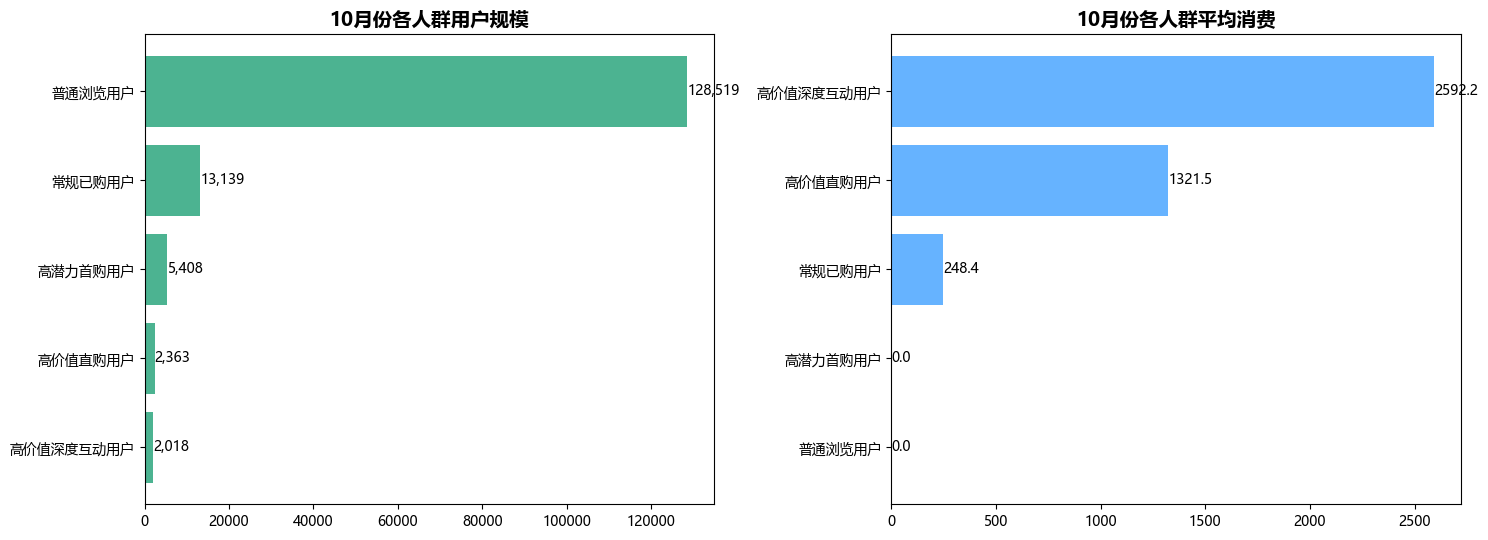

In [27]:
# ============================================================
# 各人群规模与平均消费概览（两张横向条形图并排）
# ============================================================

# 统计每个分层的用户人数（按人数从多到少排序）
seg_counts = final_df['User_Segment'].value_counts()

# 准备一张 1 行 2 列的画布：左图看规模，右图看平均消费
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# ── 左图：各人群用户规模 ──
# 画横向条形图（翻转顺序让最大的在上面），绿色系
axes[0].barh(seg_counts.index[::-1], seg_counts.values[::-1], color='#4CB391')
axes[0].set_title('10月份各人群用户规模', fontsize=14, fontweight='bold')
# 在每个条形右端标出具体人数（千分位）
for i, v in enumerate(seg_counts.values[::-1]):
    axes[0].text(v + 30, i, f'{v:,}', va='center', fontsize=10)

# ── 右图：各人群平均消费 ──
# 按平均消费升序排序后画横向条形图，蓝色系
avg_spend = final_df.groupby('User_Segment')['Total_Spending'].mean().sort_values()
axes[1].barh(avg_spend.index, avg_spend.values, color='#66b3ff')
axes[1].set_title('10月份各人群平均消费', fontsize=14, fontweight='bold')
# 在每个条形右端标出平均消费（1 位小数）
for i, v in enumerate(avg_spend.values):
    axes[1].text(v + 1, i, f'{v:.1f}', va='center', fontsize=10)

# 统一布局后展示整张图
plt.tight_layout()
plt.show()


## 10月份分层结构透视

> 说明：图例中的第 6 类 **「高价值高摩擦」在 10 月单月口径下为 0**，所以图中只会出现 5 个色段。
> 该人群必须用**观察月（11 月）的完全沉默行为**才能标记（由 `silent_buyer` 完成），而本节的
> `final_df` 只包含 10 月标签——`silent_buyer` 在后面「汇总报告：各人群 11 月转化率对比」单元才调用。

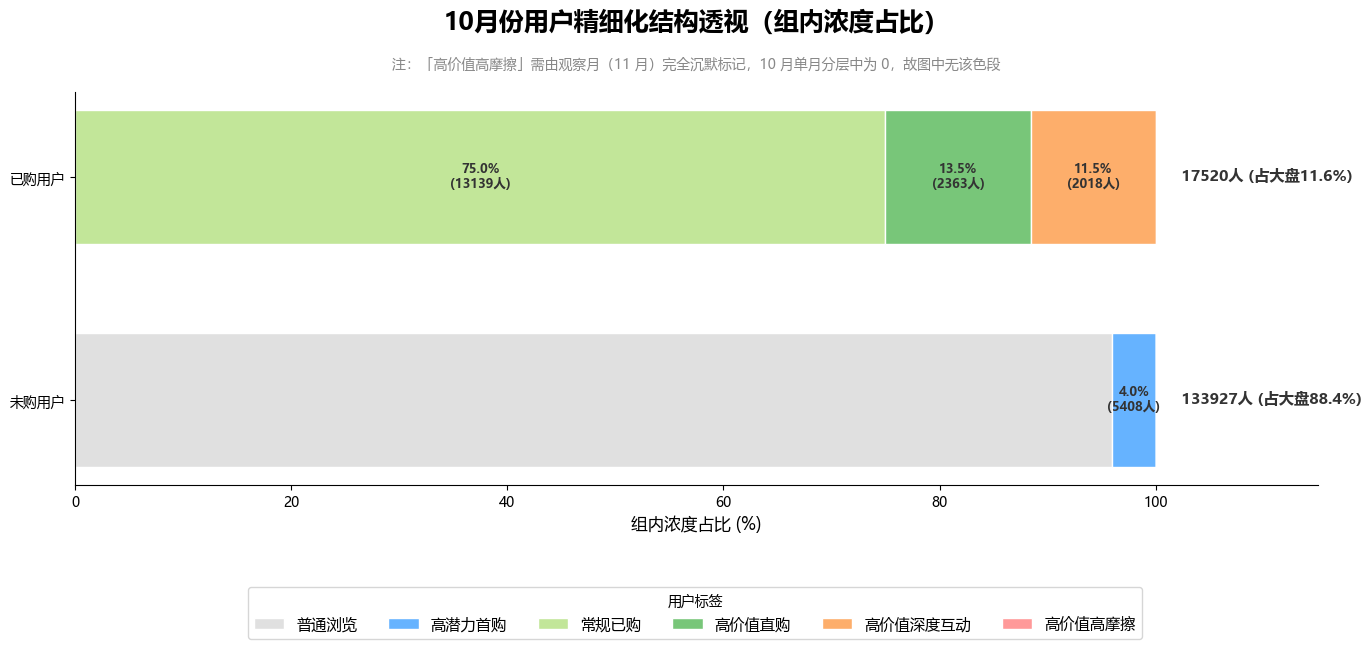

In [28]:
def plot_strategic_segments_matrix_100pct(df):
    """
    绘制 100% 组内归一化横向堆叠条形图，透视用户精细化结构。

    横轴统一为"组内浓度占比"，聚焦展示各战略人群在已购/未购两大基础
    分层内部的真实分布占比，消除底层庞大常规用户群绝对数量造成的
    "视觉坍塌"。

    Parameters:
    -----------
    df : pandas.DataFrame
        包含最终分层结果 'Base_Segment' 和 'User_Segment' 的数据框。

    Returns:
    --------
    None
        直接在前端输出图表。
    """

    # 1. 标签归纳映射
    # 把细分的 User_Segment 标签归纳成适合展示的六大类图例
    def categorize_for_plot(label):
        """把一个用户的精细化标签归并到用于绘图的六大类之一。"""
        if '高摩擦' in label:
            return '高价值高摩擦'
        elif '深度互动' in label:
            return '高价值深度互动'
        elif '直购' in label:
            return '高价值直购'
        elif '常规' in label:
            return '常规已购'
        elif '高潜力' in label:
            return '高潜力首购'
        else:
            return '普通浏览'

    # 新增一列 Plot_Category：对每个用户做标签归并（会就地修改传入的 df）
    df['Plot_Category'] = df['User_Segment'].apply(categorize_for_plot)

    # 2. 交叉表：基础分层（行） × 精细化人群（列），格子值为人数
    plot_data = pd.crosstab(df['Base_Segment'], df['Plot_Category'])

    # 规定图例列的展示顺序（普通浏览 → 高潜力首购 → … → 高价值高摩擦）
    plot_cols = ['普通浏览', '高潜力首购', '常规已购', '高价值直购', '高价值深度互动', '高价值高摩擦']
    # 若某个人群在数据里完全不存在，则补一列全 0，保证列顺序与图例一致
    # （10 月口径下「高价值高摩擦」就是这种情形：它要等观察月沉默标记，见本节下方的图中注释）
    for col in plot_cols:
        if col not in plot_data.columns:
            plot_data[col] = 0
    # 按预定的列顺序重排
    plot_data = plot_data[plot_cols]

    # 规定基础分层行的固定顺序（上：未购，下：已购）
    base_order = ['未购用户', '已购用户']
    # 按该顺序重排行；缺失的行补 0
    plot_data = plot_data.reindex(base_order).fillna(0)
    # 大盘总人数：用于计算"占大盘比例"
    total_users = len(df)

    # 3. 提前算出每一层（每一行）的总人数，后续用于归一化成百分比
    row_totals = plot_data.sum(axis=1)

    # 新建一张宽画布，用于画横向堆叠条形图
    # 画布加高一点：底部要留出放图例的空间（下面 rect 会从 16% 处开始排坐标区）
    fig, ax = plt.subplots(figsize=(14, 6.6))

    # 六大人群各自固定的配色
    colors = {
        '普通浏览': '#e0e0e0',
        '高潜力首购': '#66b3ff',
        '常规已购': '#c2e699',
        '高价值直购': '#78c679',
        '高价值深度互动': '#fdae6b',
        '高价值高摩擦': '#ff9999'
    }

    # 每根条的左侧起始位置：按百分比从 0.0 开始逐段累加
    left_pos = pd.Series([0.0] * len(plot_data), index=plot_data.index)

    # 按预定顺序逐个人群叠画堆叠段
    for category in plot_cols:
        values = plot_data[category]             # 该人群在每层里的绝对人数
        pct_values = (values / row_totals) * 100  # 归一化：该层组内占比（0-100）

        # 在当前累加位置之上叠画这一段（白边分隔各段）
        ax.barh(plot_data.index, pct_values, left=left_pos,
                label=category, color=colors[category], edgecolor='white', height=0.6)

        # 灰色"普通浏览"段不写字，其余段内部标注占比与人数
        if category != '普通浏览':
            for i, val in enumerate(values):
                if val > 0:
                    pct = pct_values.iloc[i]                   # 该段占比
                    x_pos = left_pos.iloc[i] + pct / 2          # 文字放段中央
                    if pct > 1.5:                               # 段太窄就不写字，避免重叠
                        ax.text(x_pos, i, f'{pct:.1f}%\n({int(val)}人)',
                                ha='center', va='center', color='#333333', fontsize=9, fontweight='bold')

        # 把当前段的占比累加进起始位置，作为下一段的左侧起点
        left_pos += pct_values

    # 4. 最右侧：该层总人数与占大盘比例（固定在 x=102 的文字列）
    for i, (idx, row) in enumerate(plot_data.iterrows()):
        total_bar = row.sum()                              # 该层总人数
        pct_total = (total_bar / total_users) * 100         # 该层占大盘比例
        ax.text(102, i, f' {int(total_bar)}人 (占大盘{pct_total:.1f}%)',
                ha='left', va='center', color='#333333', fontsize=11, fontweight='bold')

    # 5. 装饰：坐标范围 / 标题 / 图例 / 边框
    ax.set_xlim(0, 115)
    # 标题带「10月份」前缀：本图用的是 10 月单月分层表；
    # pad 加大到 45，给下面那行「第 6 类为何为 0」的注释留出空间
    plt.title('10月份用户精细化结构透视（组内浓度占比）', fontsize=18, pad=45, fontweight='bold')
    # 说明第 6 类「高价值高摩擦」为何是 0：它需要观察月（11 月）的完全沉默行为才能标记，
    # 而 10 月单月分层时 silent_buyer 还没被调用 → 该人群尚未生成
    ax.text(0.5, 1.05,
            '注：「高价值高摩擦」需由观察月（11 月）完全沉默标记，10 月单月分层中为 0，故图中无该色段',
            transform=ax.transAxes, ha='center', va='bottom', fontsize=10, color='#888888')
    plt.xlabel('组内浓度占比 (%)', fontsize=12)
    plt.ylabel('', fontsize=12)
    # 图例改挂到整张画布的最底部（fig.legend，单位是画布坐标）。
    # 原来的 plt.legend(bbox_to_anchor=(0.5, -0.08)) 是把图例挂在坐标区外面，
    # tight_layout 不会为它留空间 → 图例框会压住 xlabel「组内浓度占比 (%)」；
    # 现在改用 rect 在画布底部显式留出 16% 的空间放图例，两者不再重叠。
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, title='用户标签', loc='lower center',
               bbox_to_anchor=(0.5, 0.012), ncol=6, fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.tight_layout(rect=(0, 0.16, 1, 1))
    plt.show()

# 调用 100% 堆叠图函数：透视最终分层表的结构
plot_strategic_segments_matrix_100pct(final_df)


## 分层结果缓存

In [29]:

from src.analysis import build_month_tables, load_panel
from src.config import MONTHS, MONTH_CACHE_DIR, PANEL_FILE

# 分析只需这 7 列（category_code / brand 等字符串列不读，省 IO 与内存）
PANEL_COLUMNS = ['event_time', 'event_type', 'price', 'product_id', 'user_id', 'user_session', 'month']

# 7 个月面板：后续章节共用同一份，避免重复加载
panel_all = load_panel(PANEL_FILE, months=MONTHS, columns=PANEL_COLUMNS)

# 缓存目录：一个月一个文件 month_YYYY-MM.parquet（可随时删除重建）
CACHE_DIR = MONTH_CACHE_DIR   # 路径集中在 src/config.py：<项目根>/data/_month_cache

# 面板 → 月度表：month_tables['2019-11'] = 该月特征 + 该月标签（当月独立分层）
# 有缓存文件就直接读，没有才现算并落盘（首次运行约 40 秒/月）
month_tables = build_month_tables(panel_all, MONTHS, cache_dir=CACHE_DIR)
print('月度表就绪:', ', '.join(MONTHS))


  2019-10: 月度表（缓存）
  2019-11: 月度表（缓存）
  2019-12: 月度表（缓存）
  2020-01: 月度表（缓存）
  2020-02: 月度表（缓存）
  2020-03: 月度表（缓存）
  2020-04: 月度表（缓存）
月度表就绪: 2019-10, 2019-11, 2019-12, 2020-01, 2020-02, 2020-03, 2020-04


# 模型验证

## 时间外验证：7 个月数据逐对检验

在 7 个月面板上逐对运行时间外验证（基期月 t 建模 → 未来月验证），用未来月份的数据检验标签的判别力（概率分的排序有效性验证见后文「概率分 Top-k 选人」）：

- **实验一（未购人群）**：先用某个月（比如 10 月）的行为给用户打标签，再看这些人下一个月（11 月）有没有买。连续做 6 组
- **实验二（已购人群·跨月沉默）**：先看某个月（10 月）的高价值用户，在下一个月（11 月）完全没有任何动作（没浏览、没加购、没购买），这种人标记为"高价值高摩擦"（疑似流失）；然后看再下一个月（12 月）他们买没买，一共做 5 组。

实验结果解读：
- 实验一：比较"高潜力首购用户"和"普通浏览用户"的次月购买率，前者应该明显更高，而且要连续 6 个月每次都高，才说明这个标签具有价值；
- 实验二：比较"高价值沉默用户"和"普通高价值用户"的次月购买率，前者应该明显更低，而且连续 5 次验证每个月都这样——如果是，说明"跨月完全沉默"确实预示流失，可以用来做流失预警。

训练月,验证月,目标人数,目标购买率,对照人数,对照购买率,p值
2019-10,2019-11,5408,13.3%,128519,5.4%,2.2e-131
2019-11,2019-12,17612,14.0%,144891,4.7%,0.0e+00
2019-12,2020-01,21243,6.8%,182764,2.3%,0.0e+00
2020-01,2020-02,19182,9.6%,182626,2.8%,0.0e+00
2020-02,2020-03,19893,11.2%,171732,3.4%,0.0e+00
2020-03,2020-04,17555,9.0%,165265,3.6%,4.5e-262


训练月,沉默月,验证月,目标人数,目标购买率,对照人数,对照购买率,p值
2019-10,2019-11,2019-12,1384,6.9%,2997,38.6%,5.9e-103
2019-11,2019-12,2020-01,1824,6.7%,3813,33.4%,3.1e-104
2019-12,2020-01,2020-02,2042,7.9%,4280,35.4%,1.1e-118
2020-01,2020-02,2020-03,1591,9.6%,2922,41.4%,6.4e-109
2020-02,2020-03,2020-04,1848,5.9%,3112,25.8%,4.2e-68


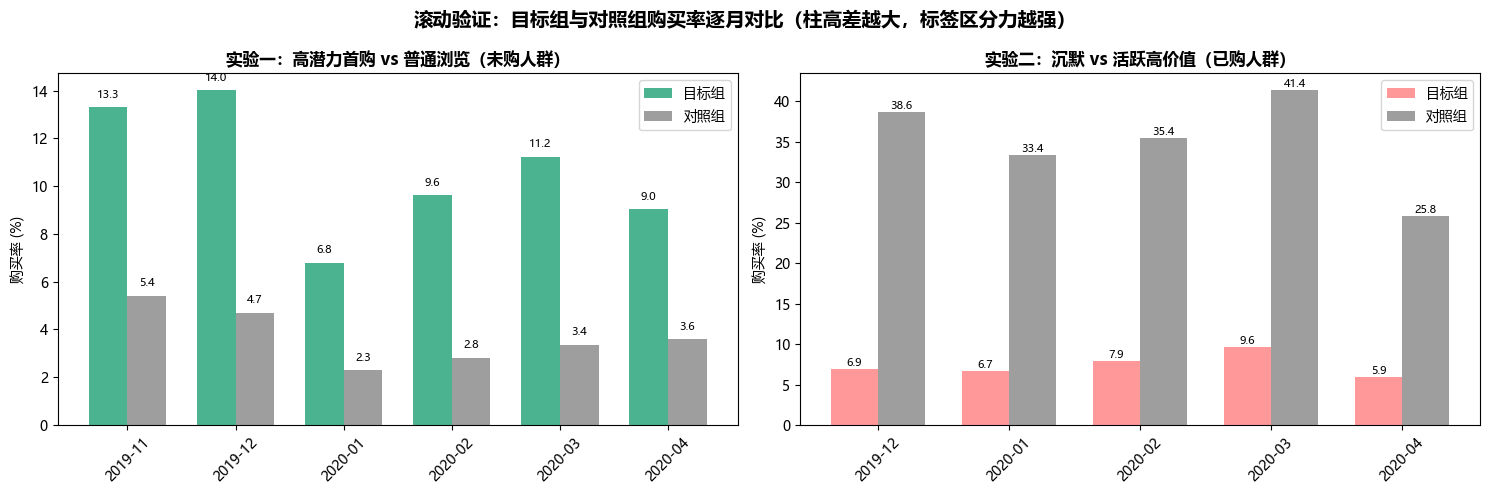

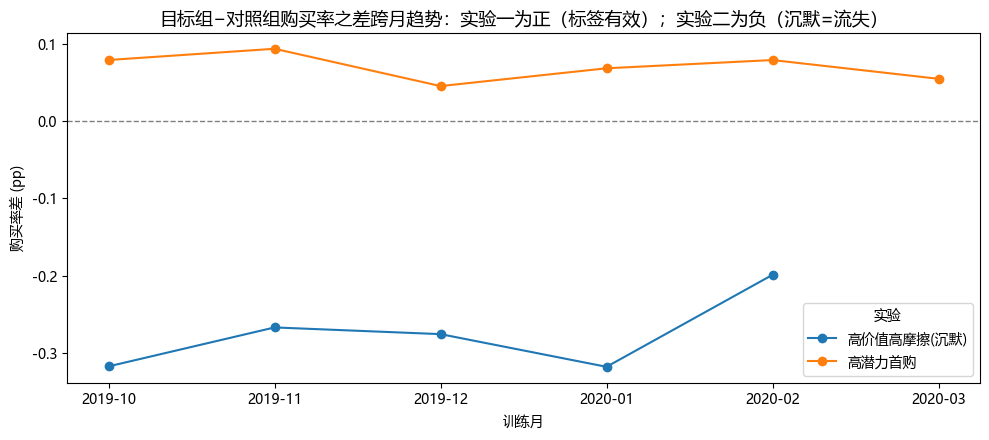

In [30]:
# ═══════════════════════════════════════════════════
# 滚动时间外验证（结果默认读取 CSV；如需重算约 15-25 分钟）
# ═══════════════════════════════════════════════════
import pandas as pd
import numpy as np
from pathlib import Path
from src.config import MONTHS, OUTPUT_ROLLING

# 改为 True 则重新计算（复用前面已建好的 7 张月度表）
RECOMPUTE = False

if RECOMPUTE:
    # 重算分支：复用前面已建好的 7 张月度表（特征/标签不再重复计算）
    from src.analysis import rolling_validation
    # 逐月对执行时间外验证，返回验证表（实验一/二逐组结果）
    res = rolling_validation(month_tables, MONTHS)
    rates = res['验证表']
    # 把验证表存成 CSV（utf-8-sig 便于 Excel 打开）
    rates.to_csv(OUTPUT_ROLLING, index=False, encoding='utf-8-sig')
else:
    # 默认分支：直接读取预计算好的结果 CSV（不做重算）
    if not Path(OUTPUT_ROLLING).exists():
        raise SystemExit(
            '未找到滚动验证结果 CSV（rolling_validation_results.csv）。\n'
            '请先运行 `python -m src.run_rolling`（需 data/panel_7months.parquet，约 15-25 分钟），'
            '或将上方 RECOMPUTE 改为 True 在本 Notebook 内重算。')
    rates = pd.read_csv(OUTPUT_ROLLING)

# ── 表格格式化：百分比 / 小数点，便于直接阅读 ──


def fmt_pct(x):
    """把小数格式化为百分数（保留 1 位小数）；缺失值显示为 —。"""
    if pd.isna(x):
        return '—'
    return f'{x:.1%}'


def fmt_p(x):
    """把 p 值格式化为科学计数法（保留 1 位小数）；缺失值显示为 —。"""
    if pd.isna(x):
        return '—'
    return f'{x:.1e}'


def fmt_rates(df, keep_cols):
    """把购买率列转成百分数文本、p 值列转成科学计数法文本，并只保留指定列。"""
    out = df.copy()
    out['目标购买率'] = out['目标购买率'].map(fmt_pct)
    out['对照购买率'] = out['对照购买率'].map(fmt_pct)
    out['p值'] = out['p值'].map(fmt_p)
    return out[keep_cols]


# 按人群把实验拆成两份：实验一（高潜力首购 vs 普通浏览）与实验二（沉默 vs 活跃高价值）
rates1 = rates[rates['实验'].str.contains('高潜力首购')].copy()
rates2 = rates[rates['实验'].str.contains('沉默')].copy()

# ── 实验一：未购人群的展示 ──
display(HTML('<h3>实验一（未购人群）</h3>'))
display(HTML('<p style="color:#555">每一行是一次时间外验证。比较<b>目标组 vs 对照组购买率</b>：'
             '目标组明显更高（且 p&lt;0.05）（ 6 行实验结果全部显著）。</p>'))
display(HTML('<p style="color:#777">小提醒：这里说的"未购用户"，指 <b>10 月这个月里没有买过东西</b>的人'
             '（看的是当月行为记录），不是"从来都没买过"的新人。所以实验一验证的是：10 月没买、但'
             '有加购没买或浏览行为的人，11 月是不是更容易买。这批人里可能混着以前买过、10 月没买的人'
             '（老客回流），不能直接当成"新客名单"。要不要严格区分"从没买过的人"，取决于运营是想拉新还是唤醒。</p>'))
# 格式化并展示实验一的结果表（保留训练月/验证月/人数/购买率/p 值等列）
display(HTML(fmt_rates(rates1, ['训练月', '验证月', '目标人数', '目标购买率',
                                '对照人数', '对照购买率', 'p值']).to_html(index=False)))

# ── 实验二：已购人群的展示 ──
display(HTML('<h3>实验二（已购人群）</h3>'))
display(HTML('<p style="color:#555">每一行是一次 3 月组验证（基期 t 高价值买家 → 观察月 t+1 完全沉默 → 验证月 t+2 是否购买'
             '）。比较<b>沉默组 vs 对照组购买率</b>：沉默组明显更低（且 p&lt;0.05）'
             '（ 5 行实验结果全部显著）。</p>'))
# 格式化并展示实验二的结果表（多一个"沉默月"列）
display(HTML(fmt_rates(rates2, ['训练月', '沉默月', '验证月', '目标人数', '目标购买率',
                                '对照人数', '对照购买率', 'p值']).to_html(index=False)))

# 拆分展示：实验一（未购人群）与实验二（已购人群·沉默）分开看，避免两类实验混排

# ── 可视化一：购买率对比（实验一 / 实验二 分面柱状图）──
# 重新按人群切出两个子表，分别喂给左右两个子图
exp1 = rates[rates['实验'].str.contains('高潜力首购')]
exp2 = rates[rates['实验'].str.contains('沉默')]


def _plot_target_vs_control(ax, group_df, title_text, color_target, color_control):
    """在指定子图上画"目标组 vs 对照组"的逐月购买率并排柱状图。"""
    # 每个验证月对应一个 x 刻度位置
    x = np.arange(len(group_df))
    # 柱宽：两组柱子并排，各占半宽
    w = 0.36
    # 目标组柱子画在刻度左侧
    ax.bar(x - w / 2, group_df['目标购买率'] * 100, w, label='目标组', color=color_target)
    # 对照组柱子画在刻度右侧
    ax.bar(x + w / 2, group_df['对照购买率'] * 100, w, label='对照组', color=color_control)
    # 在每根柱子顶端标注对应的购买率数值
    for xi, (t, c) in enumerate(zip(group_df['目标购买率'] * 100, group_df['对照购买率'] * 100)):
        ax.text(xi - w / 2, t + 0.4, f'{t:.1f}', ha='center', fontsize=8)
        ax.text(xi + w / 2, c + 0.4, f'{c:.1f}', ha='center', fontsize=8)
    # x 轴刻度 = 各验证月，旋转 45 度避免文字重叠
    ax.set_xticks(x)
    ax.set_xticklabels(group_df['验证月'], rotation=45)
    ax.set_ylabel('购买率 (%)')
    ax.set_title(title_text, fontsize=12, fontweight='bold')
    ax.legend()


# 画布：1 行 2 列，左=实验一，右=实验二
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# 左图：实验一（未购人群）目标组 vs 普通浏览对照组
_plot_target_vs_control(axes[0], exp1, '实验一：高潜力首购 vs 普通浏览（未购人群）', '#4CB391', '#9e9e9e')
# 右图：实验二（已购人群）沉默组 vs 活跃高价值对照组
_plot_target_vs_control(axes[1], exp2, '实验二：沉默 vs 活跃高价值（已购人群）', '#ff9999', '#9e9e9e')
# 整图标题：柱高差越大说明标签区分力越强
plt.suptitle('滚动验证：目标组与对照组购买率逐月对比（柱高差越大，标签区分力越强）', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ── 可视化二：购买率差跨月趋势（稳定性）──
# 透视成"训练月为行、实验为列"的购买率差矩阵，并按训练月排序
piv = rates.pivot(index='训练月', columns='实验', values='购买率差').sort_index()
# 折线图：每个实验一条线，观察购买率差是否跨月稳定
ax = piv.plot(marker='o', figsize=(10, 4.5))
# 画 y=0 参考线：线上方=目标组更高，线下方=对照组更高
ax.axhline(0, color='gray', ls='--', lw=1)
ax.set_ylabel('购买率差 (pp)')
ax.set_title('目标组−对照组购买率之差跨月趋势：实验一为正（标签有效）；实验二为负（沉默=流失）', fontsize=13)
plt.tight_layout()
plt.show()


## 汇总报告：各人群 11 月转化率对比


In [31]:
# ═══════════════════════════════════════════════════
# 汇总报告：各人群 11 月转化率对比
# ═══════════════════════════════════════════════════
from src.analysis import silent_buyer

# 已购人群“高摩擦” = 跨月完全沉默：10月高价值买家在 11 月无任何行为
# ⚠️ 口径说明：先保存 10 月基期标签（Base_User_Segment），再做沉默分流。
# 六组转化率一律按【事前基期口径】计算（分母 = 10 月全量该标签用户；高价值高摩擦为 flag 后标签）（分母 = 10 月全量该标签用户）。
# 若改用 flag 后的 User_Segment 选 VIP，只会剩“11 月仍活跃”的用户，
# 转化率变成已知未来的条件概率（存活偏差/未来信息泄漏）。

# 复制一份分层表，避免后续新增列影响别处的 final_df
final_df = final_df.copy()
# 先把 10 月基期标签存到独立列，供"事前口径"计算使用
final_df['Base_User_Segment'] = final_df['User_Segment']
# 调用沉默分流：用 11 月行为把"高价值但 11 月完全沉默"的用户标记出来
final_df = silent_buyer(final_df, nov_events)

# 逐个提取六组人群的 user_id 数组（基期口径 / 沉默后口径）
# 目标组一：高潜力首购用户（未购人群中按基期标签选取）
mask_potential = final_df['Base_User_Segment'] == '高潜力首购用户'
target_potential_ids = final_df.loc[mask_potential, 'user_id'].to_numpy()
# 对照组：普通浏览用户（基期标签）
mask_control_low = final_df['Base_User_Segment'] == '普通浏览用户'
control_low_value_ids = final_df.loc[mask_control_low, 'user_id'].to_numpy()
# 常规已购用户（基期标签）
mask_regular = final_df['Base_User_Segment'] == '常规已购用户'
target_regular_ids = final_df.loc[mask_regular, 'user_id'].to_numpy()
# 高价值直购用户（基期标签）
mask_efficient_vip = final_df['Base_User_Segment'] == '高价值直购用户'
target_efficient_vip_ids = final_df.loc[mask_efficient_vip, 'user_id'].to_numpy()
# 高价值深度互动用户（基期标签）
mask_immersive_vip = final_df['Base_User_Segment'] == '高价值深度互动用户'
target_immersive_vip_ids = final_df.loc[mask_immersive_vip, 'user_id'].to_numpy()
# 高价值高摩擦用户（沉默分流后的标签）
mask_silent = final_df['User_Segment'] == '高价值高摩擦用户'
target_silent_ids = final_df.loc[mask_silent, 'user_id'].to_numpy()


def evaluate_nov_performance(user_list, group_name):
    """评估某一人群在 11 月的转化表现；人数为 0 时返回 None 表示跳过。"""
    if len(user_list) == 0:
        return None
    # 取该人群在 11 月的行为记录
    group_nov = nov_events[nov_events['user_id'].isin(user_list)]
    # 只保留 11 月的购买事件
    nov_purchases = group_nov[group_nov['event_type'] == 'purchase']
    # 下单人数（按 user_id 去重）
    buyers = nov_purchases['user_id'].nunique()
    # 转化率 = 下单人数 / 该人群总人数
    cvr = buyers / len(user_list)
    # 11 月营收 = 购买事件价格之和
    rev = nov_purchases['price'].sum()
    # 人均消费 = 营收 / 下单人数（没人下单时为 0，避免除零）
    arppu = rev / buyers if buyers > 0 else 0
    return {
        '人群分组': group_name,
        '人数': len(user_list),
        '11月下单': buyers,
        '转化率': f"{cvr:.2%}",
        '11月营收': round(rev, 2),
        '人均消费': round(arppu, 2)
    }


# 六组待评估人群：(user_id 数组, 展示名)
groups = [
    (target_potential_ids, "高潜力首购用户"),
    (control_low_value_ids, "普通浏览用户"),
    (target_regular_ids, "常规已购用户"),
    (target_efficient_vip_ids, "高价值直购用户"),
    (target_immersive_vip_ids, "高价值深度互动用户"),
    (target_silent_ids, "高价值高摩擦用户（11月完全沉默，转化率应为0%）"),
]

# 逐组评估，跳过没有样本的分组，把有效行汇总成报告表
report_rows = []
for ids, name in groups:
    row = evaluate_nov_performance(ids, name)
    if row is not None:
        report_rows.append(row)
report = pd.DataFrame(report_rows)
# 以 HTML 表格展示最终转化率报告
display(HTML(report.to_html(index=False)))


人群分组,人数,11月下单,转化率,11月营收,人均消费
高潜力首购用户,5408,719,13.30%,399843.12,556.11
普通浏览用户,128519,6959,5.41%,3257092.60,468.04
常规已购用户,13139,2854,21.72%,1529278.19,535.84
高价值直购用户,2363,865,36.61%,1179416.07,1363.49
高价值深度互动用户,2018,927,45.94%,1567187.28,1690.60
高价值高摩擦用户（11月完全沉默，转化率应为0%）,4381,1792,40.90%,2746603.35,1532.70


## 概率分 Top-k 选人


In [32]:
# 打分：调用纯工具 LR_predict_rank（预测『预测月』的购买概率 + 在传入用户内部排名）
# ⚠️ 时间窗口（由工具函数内部保证无泄漏）：
#    - 训练：更早月份的「训练行为月 → 训练结果月」样本（该月全体用户），一个 LR 模型；
#    - 打分：只对传入的用户名单打分，名次只在这些用户内部计算（1 ~ N）；
#    - 因此 10 月是最早的建模月、没有更早的训练行为月，无法打分，打分最早从 11 月开始。
import numpy as np
from src.analysis import LR_predict_rank
from src.config import POOL_TOP_RATIO

# 本轮训练结果月
SCORE_MONTH = '2019-11'

# ── 第一步：取该月的月度表（特征 + 该月标签，已由"月度表缓存"cell 算好）──
# 变量名用 nov_df：这张表是 11 月特征 + 11 月标签，
# 不要和前面「用户价值分层」章节那份 10 月分层表 final_df 混用（同名极易误读）
nov_df = month_tables[SCORE_MONTH].copy()

# 打分结果列先占位：本次只对"高潜力首购用户"打分，其余标签留 NaN
nov_df['First_Purchase_Prob'] = np.nan
nov_df['First_Purchase_Rank'] = np.nan
# 已购两列也先占位：导出名单的函数要求这些列存在；后续要对已购用户打分时在这里补齐
nov_df['Repurchase_Prob'] = np.nan
nov_df['Repurchase_Rank'] = np.nan

# ── 第二步：对"高潜力首购用户"调用工具函数──
# 后续要给别的标签打分时，照着下面两行再写一次即可（工具函数本身与人群无关）
target_ids = nov_df.loc[nov_df['User_Segment'] == '高潜力首购用户', 'user_id'].to_numpy()
# 传入 7 张月度表：函数内部用更早月份的历史样本训练，再对本轮名单打分
ranked = LR_predict_rank(month_tables, SCORE_MONTH, target_ids)
# 按 user_id 把概率与名次映射回名单
nov_df['First_Purchase_Prob'] = nov_df['user_id'].map(ranked.set_index('user_id')['Prob'])
nov_df['First_Purchase_Rank'] = nov_df['user_id'].map(ranked.set_index('user_id')['Rank'])
print(f'已打分：高潜力首购用户 {len(target_ids):,} 人（名次 1 ~ {len(target_ids):,}）')

# ── 第三步：调用方口径的"优先触达"标记（名单内前 POOL_TOP_RATIO）──
in_list = nov_df['First_Purchase_Rank'].notna()
k = int(np.ceil(int(in_list.sum()) * POOL_TOP_RATIO))
nov_df['TopK_Flag'] = np.nan
nov_df.loc[in_list, 'TopK_Flag'] = (nov_df.loc[in_list, 'First_Purchase_Rank'] <= k).astype(int)
print(f"历史窗口训练（无泄漏）：候选名单（{SCORE_MONTH} 高潜力首购）{int(in_list.sum()):,} 人 → "
      f"TopK_Flag 标记名单内前 {POOL_TOP_RATIO:.0%}（{int((nov_df['TopK_Flag'] == 1).sum()):,} 人）优先触达")

# ── 预览：按首购名次取前 10 ──
top_preview = (nov_df.loc[nov_df['User_Segment'] == '高潜力首购用户',
                            ['user_id', 'Exploration', 'Friction',
                             'First_Purchase_Prob', 'First_Purchase_Rank', 'TopK_Flag']]
               .sort_values('First_Purchase_Rank').head(10))
display(HTML(top_preview.to_html(index=False)))

# ── 名单规模核对 ──
print('TopK_Flag=1 的人数:', int(nov_df['TopK_Flag'].sum()))


已打分：高潜力首购用户 17,612 人（名次 1 ~ 17,612）
历史窗口训练（无泄漏）：候选名单（2019-11 高潜力首购）17,612 人 → TopK_Flag 标记名单内前 50%（8,806 人）优先触达


user_id,Exploration,Friction,First_Purchase_Prob,First_Purchase_Rank,TopK_Flag
568778435,7.319523,3,0.749083,1.0,1.0
568826117,4.697618,13,0.495025,2.0,1.0
516308435,4.190522,3,0.393192,3.0,1.0
551679343,3.862066,1,0.380722,4.0,1.0
568777364,3.862815,1,0.360171,5.0,1.0
513778820,4.076560,2,0.350137,6.0,1.0
564442389,3.776180,5,0.342590,7.0,1.0
515188887,3.655779,4,0.322126,8.0,1.0
535717297,3.548007,3,0.318400,9.0,1.0
513674548,3.665256,3,0.315864,10.0,1.0


TopK_Flag=1 的人数: 8806


### 排序有效性验证

工具函数 `LR_predict_rank` 只输出"概率 + 名次"，它到底有没有用，要拿**预测月的真实购买**来验证：把概率分排序后分桶，看"分越靠前、预测月购买率是否越高"。

下面把这个验证**推广到每一轮打分（训练结果月 2019-11 ~ 2020-03；10 月是最早的建模月、无法打分）**：

- 每轮对"高潜力首购用户"打分，比较**名单前 50%（LR Top-k）**、**整个名单**、**全体未购用户基线**三者的预测月购买率；
- 再按名次做 4 桶，检查各桶购买率是否随名次变差而下降（单调性）。

全部为时间外验证（用训练结果月的特征打分、用预测月的购买结果验证；训练严格早于本轮的训练结果月，无泄漏）。


  2019-11 完成（→2019-12 预测月）
  2019-12 完成（→2020-01 预测月）
  2020-01 完成（→2020-02 预测月）
  2020-02 完成（→2020-03 预测月）
  2020-03 完成（→2020-04 预测月）


训练结果月,预测月,名单人数,基线(全体未购),全体名单,LR Top-k,Top-k人数,Top-k提升(pp)
2019-11,2019-12,17612,5.70%,14.02%,17.27%,8806,+3.25
2019-12,2020-01,21243,2.76%,6.80%,8.26%,10622,+1.46
2020-01,2020-02,19182,3.46%,9.62%,12.19%,9591,+2.57
2020-02,2020-03,19893,4.18%,11.24%,14.40%,9947,+3.16
2020-03,2020-04,17555,4.11%,9.03%,11.83%,8778,+2.79


高潜力首购名单——名次分桶的预测月购买率（越靠前越高 = 排序有效）：
  2019-11→2019-12: 前10% 22.02% | 10-25% 17.38% | 25-50% 15.31% | 后50% 10.78%
  2019-12→2020-01: 前10% 10.73% | 10-25% 8.69% | 25-50% 7.00% | 后50% 5.34%
  2020-01→2020-02: 前10% 18.39% | 10-25% 13.07% | 25-50% 9.18% | 后50% 7.05%
  2020-02→2020-03: 前10% 20.40% | 10-25% 14.95% | 25-50% 11.66% | 后50% 8.08%
  2020-03→2020-04: 前10% 15.21% | 10-25% 11.70% | 25-50% 10.55% | 后50% 6.24%


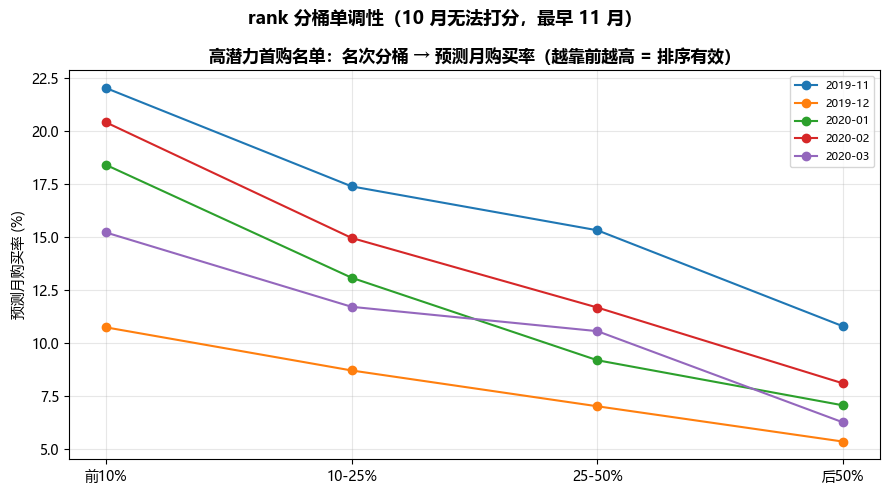

In [33]:
# ═══════════════════════════════════════════════════
# 排序有效性验证：LR_predict_rank 给出的名次是否有效
# （高潜力首购名单视角，覆盖每一轮打分）
# 说明：直接复用"月度表缓存"cell 已备好的 7 张月度表（特征 + 标签），不再重复构建。
# ═══════════════════════════════════════════════════
import numpy as np
import pandas as pd
from src.analysis import _next_month, LR_predict_rank
from src.config import MONTHS, POOL_TOP_RATIO

# 月度表：来自前面的"月度表缓存"cell（每月一张：该月特征 + 该月标签）

# 可打分的月份（= 训练结果月）：10 月是最早的建模月、无法打分；
# 且训练结果月的下一个月（预测月）必须在面板内，否则没有结果可验证
score_months = []
for m in MONTHS:
    if m > '2019-10' and _next_month(m) in MONTHS:
        score_months.append(m)

# rank 分桶的边界（按人数比例分 4 桶）与各桶名字
BUCKETS = [(0.0, 0.10, '前10%'), (0.10, 0.25, '10-25%'), (0.25, 0.50, '25-50%'), (0.50, 1.0, '后50%')]


def bucket_rates(rank_sorted_df, y_col):
    """按 rank 升序排序后按人数比例切 4 桶，返回各桶 y 均值（越靠前越高 = 排序有效）。"""
    n = len(rank_sorted_df)
    if n == 0:
        return [np.nan] * len(BUCKETS)
    rates, start = [], 0
    for lo, hi, _ in BUCKETS:
        end = int(np.ceil(hi * n))
        rates.append(rank_sorted_df.iloc[start:end][y_col].mean())
        start = end
    return rates


# ── 每一轮打分（训练结果月）：对"高潜力首购用户"调用纯工具函数 ──
list_rows, list_buckets = [], {}
for sm in score_months:
    nm = _next_month(sm)  # 预测月 = 训练结果月的下一个月
    # 预测月里真实下单的用户集合 → 作为验证标签（打分时不可见）
    # 买过 ⇔ 该月表的 Purchase_Frequency > 0（与事件表口径等价）
    table_nm = month_tables[nm]
    buyers_nm = set(table_nm.loc[table_nm['Purchase_Frequency'] > 0, 'user_id'])

    # 训练结果月的月度表（来自月度表缓存）
    seg_sc = month_tables[sm].copy()
    seg_sc['bought'] = seg_sc['user_id'].isin(buyers_nm).astype(int)

    # 打分名单 = 该月"高潜力首购用户"（名次在名单内部 1 ~ N）
    target_ids = seg_sc.loc[seg_sc['User_Segment'].eq('高潜力首购用户'), 'user_id'].to_numpy()
    scored = LR_predict_rank(month_tables, sm, target_ids)
    scored = scored.merge(seg_sc[['user_id', 'bought']], on='user_id', how='left')
    # 调用方口径的 Top-k：名单内前 POOL_TOP_RATIO
    k = int(np.ceil(len(scored) * POOL_TOP_RATIO))
    top = scored[scored['Rank'] <= k]
    # 基线 = 该月全体未购用户的购买率
    baseline = seg_sc.loc[seg_sc['Purchase_Frequency'].eq(0), 'bought'].mean()
    list_rows.append({'训练结果月': sm, '预测月': nm, '名单人数': len(scored),
                      '基线(全体未购)': baseline,
                      '全体名单': scored['bought'].mean(),
                      'LR Top-k': top['bought'].mean() if len(top) else np.nan,
                      'Top-k人数': len(top)})
    list_buckets[sm] = bucket_rates(scored.sort_values('Rank'), 'bought')
    print(f'  {sm} 完成（→{nm} 预测月）')

# 把逐月记录变成表格，并算出 Top-k 相对全体名单的提升（百分点）
list_df = pd.DataFrame(list_rows)
list_df['Top-k提升(pp)'] = (list_df['LR Top-k'] - list_df['全体名单']) * 100


def _fmt_pct2(x):
    """把小数格式化为两位百分数；缺失值显示为 —。"""
    if pd.isna(x):
        return '—'
    return f'{x:.2%}'


def _fmt_pp(x):
    """把差值格式化为带符号的两位小数（百分点）；缺失值显示为 —。"""
    if pd.isna(x):
        return '—'
    return f'{x:+.2f}'


# 把展示用的三列购买率与提升列都转成易读文本
show = list_df.copy()
for c in ['基线(全体未购)', '全体名单', 'LR Top-k']:
    show[c] = show[c].map(_fmt_pct2)
show['Top-k提升(pp)'] = show['Top-k提升(pp)'].map(_fmt_pp)
# 展示高潜力首购名单的逐月时间外验证表
display(HTML('<h3>高潜力首购名单：LR Top-k vs 全体名单 vs 基线（逐月时间外验证）</h3>'))
display(HTML(show.to_html(index=False)))

# 打印逐月分桶的预测月购买率
print('高潜力首购名单——名次分桶的预测月购买率（越靠前越高 = 排序有效）：')
for sm, rates_by_bucket in list_buckets.items():
    parts = []
    for bucket, rate in zip(BUCKETS, rates_by_bucket):
        bucket_name = bucket[2]
        parts.append(f'{bucket_name} {rate:.2%}')
    bucket_text = ' | '.join(parts)
    print(f'  {sm}→{_next_month(sm)}: ' + bucket_text)

# ── 分桶单调性图 ──
# 画图意图：若 LR 排序有效，越靠前的 rank 分桶购买率应越高（曲线单调下降）
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(BUCKETS))
for sm, rates_by_bucket in list_buckets.items():
    ax.plot(x, np.array(rates_by_bucket) * 100, marker='o', label=sm)
ax.set_xticks(x)
ax.set_xticklabels([b[2] for b in BUCKETS])
ax.set_ylabel('预测月购买率 (%)')
ax.set_title('高潜力首购名单：名次分桶 → 预测月购买率（越靠前越高 = 排序有效）', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.suptitle('rank 分桶单调性（10 月无法打分，最早 11 月）', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 结果持久化

In [34]:
# ============================================================
# 名单导出：供运营直接使用的 CSV 文件
# ============================================================
import importlib
import src.analysis as _ana

importlib.reload(_ana)
# 导入名单导出函数
from src.analysis import export_tracking
from src.config import OUTPUT_TRACKING

# 候选触达名单：11 月高潜力首购用户（名单内按概率分排名，TopK_Flag=1 优先触达）
# nov_df 来自上一个单元：month_tables['2019-11'] 的 11 月特征 + 11 月标签
tracking_cand = export_tracking(nov_df, OUTPUT_TRACKING,
                                segments=['高潜力首购用户'])
print(f"已导出候选触达名单 {len(tracking_cand):,} 名用户（11月高潜力首购）至 {OUTPUT_TRACKING}")
# 注：跨月沉默高价值（11 月基期高价值在 12 月完全沉默）需在 12 月底用 silent_buyer
#     单独判定（用于 1 月召回），不在本次 11 月打分名单内——沉默是事后标记，天然滞后一个月。


已导出候选触达名单 17,612 名用户（11月高潜力首购）至 D:\Code\ecommerce-user-behavior-segmentation\results\tracked_users_list_Nov.csv


## 标签迁移分析

固定基期月（2019-10）分层后，逐月追踪**同一批用户**（队列：固定 10 月那批用户，看他们后续月的标签变化；7 个月用户面板，5% 抽样约 78 万用户），用**冻结的 10 月阈值**（固定沿用 10 月拟合的切分线，不让每月重算）重算后续月标签——高价值直购 / 深度互动 / 常规已购 是保持、降级、升级还是沉默？

- **① 标签保持 / 转化**：各 10 月标签在后续月的标签构成（"无任何活动" = 当月完全无任何行为）；
- **② 标签保持率**：仍保持原标签的比例随时间变化（越高 = 标签越稳定，下降越快 = 越容易转化）。

> **为什么必须冻结阈值**：若不冻结，每月重新拟合的 GMM / 分位阈值会漂移（如 Exploration 阈值从 −0.07 漂到 −1.01），标签变化会被"尺子变了"污染，无法区分是用户变了还是阈值变了。冻结阈值后跨月标签才可比。


In [35]:
# ═══════════════════════════════════════════════════
# 队列迁移分析（结果默认读取 CSV；如需重算运行 python -m src.run_cohort，约 10-20 分钟）
# ═══════════════════════════════════════════════════
import importlib
import src.config as _cfg
# 防御：kernel 早于本版本启动时，刷新配置缓存
importlib.reload(_cfg)
import src.analysis as _ana
importlib.reload(_ana)
import os
from pathlib import Path
import pandas as pd
import numpy as np
from src.config import OUTPUT_COHORT_LABELS

# 结果文件不存在时报错退出，提示用户先跑 run_cohort.py（防御性检查）
if not Path(OUTPUT_COHORT_LABELS).exists():
    raise SystemExit(
        '未找到 cohort_frozen_labels.csv。请先运行 `python -m src.run_cohort`'
        '（需 7 个月面板，约 10-20 分钟）。')
# 读取冻结标签结果：每个用户在每个月的标签构成
fl = pd.read_csv(OUTPUT_COHORT_LABELS)
# 标签的固定展示顺序（迁移分析中统一使用这个顺序）
LABELS_ORDER = ['普通浏览用户', '高潜力首购用户', '常规已购用户', '高价值直购用户', '高价值深度互动用户', '高价值高摩擦用户']


### 结论：所有标签都稳不住

**① 标签保持率**（10 月各标签队列在后续月仍保持原标签的比例，越高 = 越稳定）：

| 10 月标签 | 11 月 | 2020-01 | 2020-04 |
|---|---:|---:|---:|
| 普通浏览 | 32.3% | 24.6% | 17.1% |
| 高潜力首购 | 16.7% | 7.6% | 5.1% |
| 常规已购 | 16.2% | 8.5% | 6.1% |
| 高价值直购 | 10.9% | 5.4% | 1.8% |
| 高价值深度互动 | 18.8% | 7.8% | 2.3% |

所有标签的次月保持率都只有 **10.9%~32.3%**，6 个月后大多降至 **1.8%~17.1%** —— 标签是"月度快照"，不是持久属性。

原因：标签按"当月是否购买 + 价值指数"定义，而用户购买天然是间歇性的，某月不买就会掉进"未购 / 普通浏览"或"无任何活动（完全无行为）"桶。唯一例外是**普通浏览**最"稳"（32.4%）——但它不是粘性强，而是"未购 + 低探索"的默认落点，用户不买就落回这里，是"稳定容器"而非"稳定客户"。

**② 转化去向**（详见下方各标签构成图，以 11 月为例）：
- **普通浏览**：56.5% 无任何活动、32.3% 保持、5.8% 变高潜力首购、5.5% 升级已购；
- **高潜力首购**：34.0% 无任何活动、36.0% 变普通浏览、16.7% 保持、10.2% 变常规已购、3.1% 升级高价值；
- **常规已购**：40.5% 无任何活动、28.5% 变普通浏览、16.2% 保持、9.2% 变高潜力首购、5.5% 升级高价值；
- **高价值直购**：38.1% 无任何活动、19.4% 变普通浏览、18.7% 降级常规已购、10.9% 保持、7.0% 升级深度互动、5.9% 变高潜力首购；
- **高价值深度互动**：24.0% 无任何活动、20.2% 变普通浏览、21.6% 降级常规已购、18.8% 保持、5.6% 变直购、9.9% 变高潜力首购。

**③ 商业发现**：
1. **普通浏览是"稳定容器"**：保持率最高（32.3%）但这是"不买就落回"的默认桶，不代表用户粘性；真正要运营的是它内部浮现的高潜力信号（5.8% 变高潜力首购）；
2. **高价值深度互动粘性最强（购买标签中）**：无任何活动占比最低（11 月 24%）、次月购买占比最高（46.0% = 常规 21.6% + 直购 5.6% + 深度互动 18.8%）→ 适合长期会员 / 新品内测运营；
3. **常规已购流失风险最高**：40.5% 次月无任何活动，6 个月后约 70% 无任何活动 → 需要及时唤醒触达；
4. **无任何活动 ≠ 永久流失**：标签基于当月行为，用户重新活跃后会回到相应标签（如高价值直购 2020-02 有 7.9% 回到常规已购）→ 沉默高价值用户值得定向召回；
5. **运营名单必须按月刷新**：标签用于"当月选人 + 差异化话术"，不能一劳永逸。


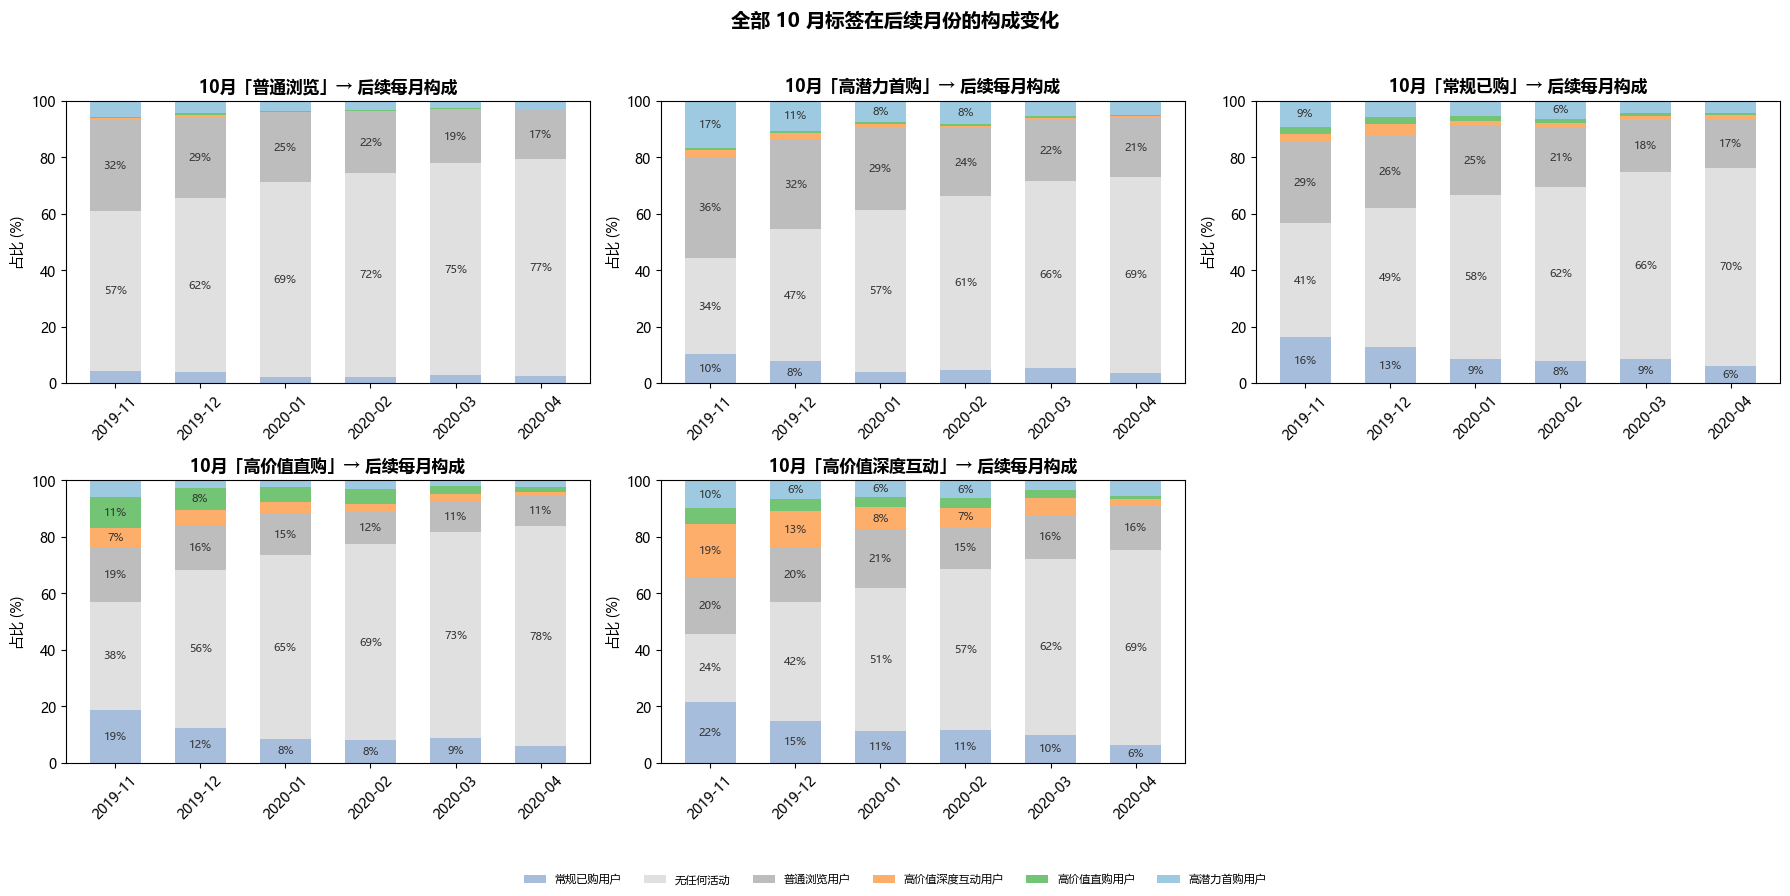

In [36]:
# ═══════════════════════════════════════════════════
# 各标签逐月构成（全部 5 个 10 月标签）
# 每个标签一张堆叠图：x = 时间（月份），堆叠 = 该月用冻结阈值重算的标签占比
# 与基期标签同色的块 = 保持原标签；浅灰 = 无任何活动；深灰/蓝 = 转化为其他标签
# ═══════════════════════════════════════════════════
import importlib
import src.config as _cfg
# 防御：kernel 早于本版本启动时，刷新配置缓存
importlib.reload(_cfg)
import src.analysis as _ana
importlib.reload(_ana)
import pandas as pd
import numpy as np
from pathlib import Path
from src.config import OUTPUT_COHORT_LABELS

# 结果文件不存在时报错退出，提示用户先跑 run_cohort.py（防御性检查）
if not Path(OUTPUT_COHORT_LABELS).exists():
    raise SystemExit(
        '未找到 cohort_frozen_labels.csv。请先运行 `python -m src.run_cohort`'
        '（需 7 个月面板，约 10-20 分钟）。')
# 读取冻结标签结果
fl = pd.read_csv(OUTPUT_COHORT_LABELS)

# 基期（10 月）的全部标签：迁移图的"出发状态"
ALL_LABELS = ['普通浏览用户', '高潜力首购用户', '常规已购用户', '高价值直购用户', '高价值深度互动用户']
# 各状态在堆叠图中的固定配色
COLOR_MAP = {
    '普通浏览用户': '#bdbdbd', '高潜力首购用户': '#9ecae1',
    '常规已购用户': '#a6bddb', '高价值直购用户': '#74c476', '高价值深度互动用户': '#fdae6b',
    '无任何活动': '#e0e0e0',
}

# 动态标签列：除了"基期标签"与"month"两列外，其余每列是一个后续月份
lab_cols = [c for c in fl.columns if c not in ('基期标签', 'month')]
# 画布：2 行 3 列（5 个标签 + 1 个空位），每个标签一张堆叠图
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

# 逐个基期标签绘制"后续每月构成"堆叠图
for i, lab in enumerate(ALL_LABELS):
    ax = axes[i]
    # 取出该基期标签的用户在后续各月的占比（按月份排序，月份为索引）
    sub = fl[fl['基期标签'] == lab].set_index('month')[lab_cols].sort_index()
    # 堆叠起点：每根柱从 0 开始，逐段累加
    bottom = np.zeros(len(sub))
    # 每个后续月份状态画一段堆叠
    for col in lab_cols:
        vals = sub[col].to_numpy() * 100
        # 画该状态在这根柱上的占比段
        ax.bar(sub.index, vals, bottom=bottom, label=col,
               color=COLOR_MAP.get(col, '#999999'), width=0.6)
        # 占比足够大的段内部标注百分比数字
        for xi, v in enumerate(vals):
            if v >= 6:
                ax.text(xi, bottom[xi] + v / 2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=8, color='#333333')
        # 把当前段高度累加进堆叠起点
        bottom += vals
    # 子图标题：10 月「该标签」→ 后续每月构成
    ax.set_title(f'10月「{lab.replace("用户", "")}」→ 后续每月构成', fontsize=12, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.set_ylabel('占比 (%)')
    ax.tick_params(axis='x', rotation=45)
# 第 6 个位置没有数据，隐藏
axes[5].axis('off')
# 从第一张子图取图例（各子图用的状态与配色一致），统一放在图下方
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6, fontsize=8, frameon=False)
# 整图标题 + 为底部图例预留空间后展示
plt.suptitle('全部 10 月标签在后续月份的构成变化',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()
